In [5]:
import pandas as pd
import numpy as np
import mglearn
import matplotlib.pyplot as plt

In [2]:
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

#データをロードして分割
cancer = load_breast_cancer()
x_train, x_test, y_train, y_test = train_test_split(cancer.data,
                                                     cancer.target, 
                                                     random_state=0
                                                    )

#訓練データの最小値と最大値を計算
scaler = MinMaxScaler().fit(x_train)
x_train_scaled = scaler.transform(x_train)

svm = SVC()
svm.fit(x_train_scaled, y_train)

x_test_scaled = scaler.transform(x_test)
print("Test score:{:.2f}".format(svm.score(x_test_scaled, y_test)))




Test score:0.97


In [3]:
#GridSearchCVを使って最適なパラメータを探索してみる
from sklearn.model_selection import GridSearchCV

#説明のためのコード
#本来ならば、訓練データをさらに分割して、交差検証を行うのが望ましい
param_grid = {
    "C":[0.001, 0.01, 0.1, 1, 10, 100],
    "gamma":[0.001, 0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    SVC(), 
    param_grid, 
    cv=5
)

grid.fit(x_train_scaled, y_train)

print("Best set score:{:.2f}".format(grid.best_score_))
print("Best parameters:{}".format(grid.best_params_))

Best set score:0.98
Best parameters:{'C': 1, 'gamma': 1}


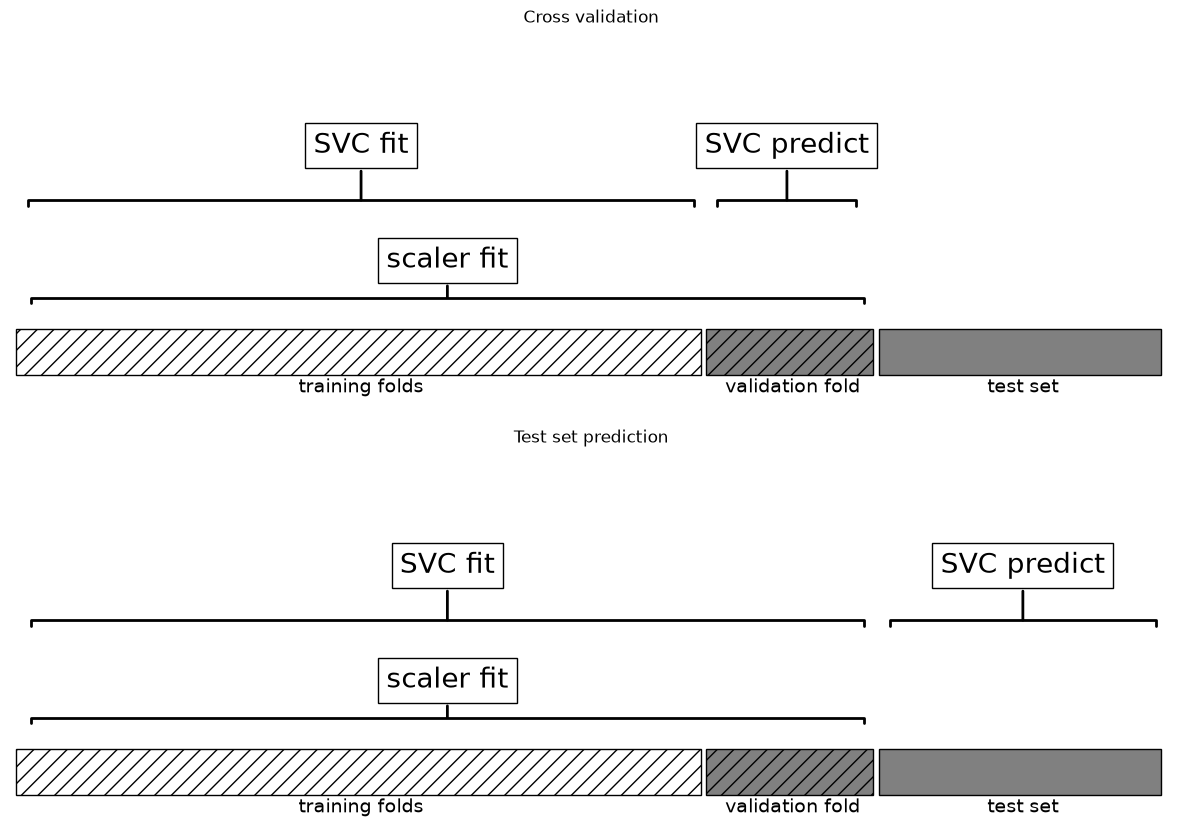

In [ ]:
#モデル構築過程において、検証データは全く新しいデータでなければならないのに、この場合には
#交差検証の検証データがその要件を満たしていない
#前処理をする前に交差検証のためのデータ分割を行う必要がある
mglearn.plots.plot_improper_processing()

- パイプラインの構築

In [ ]:
from sklearn.pipeline import Pipeline

#ここでは二つのステップを作っている
pipe = Pipeline([
    ("scaler",MinMaxScaler()),
    ("svm",SVC())
])

pipe.fit(x_train,y_train)

#こえは最初にやったものと同じ結果になる
print("Test score:{:.2f}".format(pipe.score(x_test, y_test)))

Test score:0.97
